In [1]:
# CAREER NAVIGATOR
# ANN - CAREER DOMAIN PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import random
import warnings
import tensorflow as tf

from pathlib import Path

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_ROOT)
print("Processed Data:", PROCESSED_DIR)
print("Model Directory:", MODEL_DIR)
print("Report Directory:", REPORT_DIR)

Project Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator
Processed Data: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\dataset\processed
Model Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models
Report Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation


In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy").astype("float32")
X_val = np.load(PROCESSED_DIR / "X_val.npy").astype("float32")
X_test = np.load(PROCESSED_DIR / "X_test.npy").astype("float32")

y_train = np.load(
    PROCESSED_DIR / "y_train_domain.npy"
).astype("int32")

y_val = np.load(
    PROCESSED_DIR / "y_val_domain.npy"
).astype("int32")

y_test = np.load(
    PROCESSED_DIR / "y_test_domain.npy"
).astype("int32")

print("Career domain dataset loaded successfully!")

print("\nInput dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget dimensions:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Career domain dataset loaded successfully!

Input dimensions:
Training: (10500, 65)
Validation: (2250, 65)
Testing: (2250, 65)

Target dimensions:
Training: (10500,)
Validation: (2250,)
Testing: (2250,)


In [4]:
domain_encoder = joblib.load(
    MODEL_DIR / "domain_encoder.joblib"
)

class_names = domain_encoder.classes_
num_classes = len(class_names)

print("Career Domain Classes:")

for index, class_name in enumerate(class_names):
    print(f"{index} = {class_name}")

print("\nNumber of classes:", num_classes)

assert num_classes == 6
assert set(np.unique(y_train)) == set(range(num_classes))

Career Domain Classes:
0 = Artificial Intelligence & Machine Learning
1 = Cloud Computing
2 = Cybersecurity
3 = Data Science
4 = Software Development
5 = UI/UX Design

Number of classes: 6


,Career Domain,Count,Percentage
0,Artificial Intelligence & Machine Learning,1115,10.62
1,Cloud Computing,1072,10.21
2,Cybersecurity,2063,19.65
3,Data Science,1078,10.27
4,Software Development,3872,36.88
5,UI/UX Design,1300,12.38


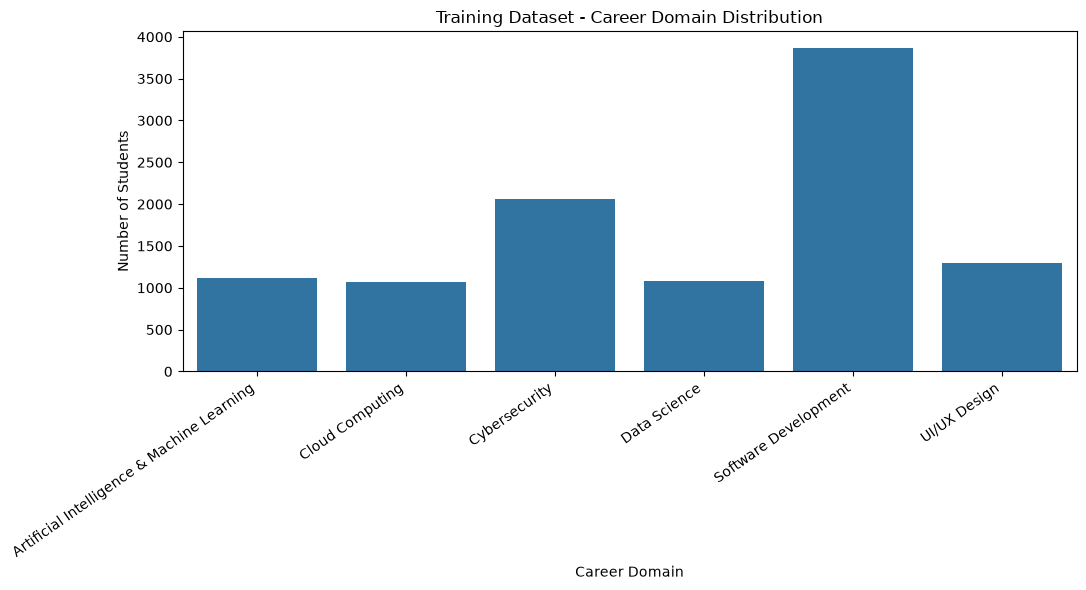

In [5]:
domain_distribution = pd.DataFrame({
    "Career Domain": class_names,
    "Count": [
        np.sum(y_train == index)
        for index in range(num_classes)
    ]
})

domain_distribution["Percentage"] = (
    domain_distribution["Count"] /
    len(y_train) * 100
)

display(domain_distribution.round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    data=domain_distribution,
    x="Career Domain",
    y="Count"
)

plt.title("Training Dataset - Career Domain Distribution")
plt.xlabel("Career Domain")
plt.ylabel("Number of Students")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [6]:
domain_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(num_classes, activation="softmax")
])

domain_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

domain_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,982 (74.15 KB)

 Trainable params: 18,982 (74.15 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
domain_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "ann_domain_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

print("Career domain callbacks configured!")

Career domain callbacks configured!


In [8]:
domain_history = domain_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=domain_callbacks,
    verbose=1
)

print("\nCareer domain ANN training completed!")
print("Epochs trained:", len(domain_history.history["loss"]))
print("Best validation loss:", min(domain_history.history["val_loss"]))

Epoch 1/100
311/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3467 - loss: 1.6484
Epoch 1: val_loss improved from None to 1.55034, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3506 - loss: 1.6434 - val_accuracy: 0.3920 - val_loss: 1.5503 - learning_rate: 0.0010
Epoch 2/100
305/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3911 - loss: 1.5711
Epoch 2: val_loss improved from 1.55034 to 1.54259, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_best.keras

Epoch 2: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3939 - loss: 1.5678 - val_accuracy: 0.3

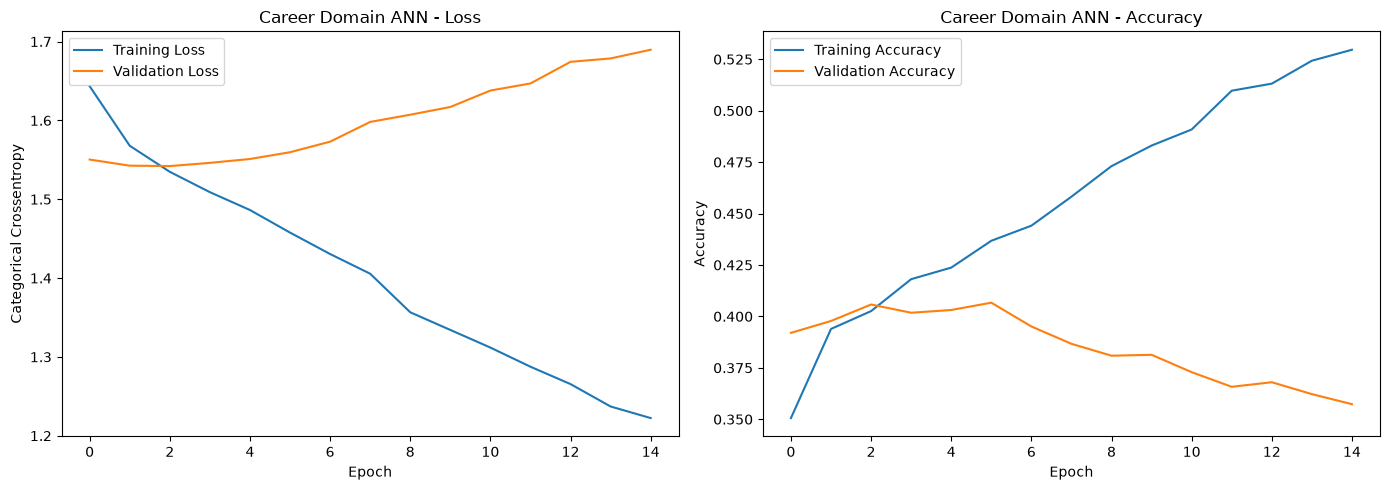

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    domain_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    domain_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Career Domain ANN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical Crossentropy")
axes[0].legend()

axes[1].plot(
    domain_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    domain_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Career Domain ANN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
domain_probabilities = domain_ann.predict(
    X_val,
    verbose=0
)

domain_predictions = np.argmax(
    domain_probabilities,
    axis=1
)

print("Validation predictions generated!")

print("\nSample predicted probabilities:")

display(pd.DataFrame(
    domain_probabilities[:10],
    columns=class_names
).round(4))

print("\nSample predicted career domains:")

print(
    domain_encoder.inverse_transform(
        domain_predictions[:10]
    )
)

Validation predictions generated!

Sample predicted probabilities:


,Artificial Intelligence & Machine Learning,Cloud Computing,Cybersecurity,Data Science,Software Development,UI/UX Design
0,0.0254,0.0458,0.0373,0.0578,0.7137,0.1200
1,0.0611,0.1477,0.1145,0.0557,0.5552,0.0658
2,0.0403,0.0306,0.4083,0.0527,0.3763,0.0918
3,0.1025,0.0869,0.1552,0.3844,0.2217,0.0494
4,0.0648,0.0444,0.1525,0.2640,0.3294,0.1450
5,0.0709,0.0590,0.1157,0.1024,0.5777,0.0743
6,0.0711,0.1575,0.1450,0.1342,0.3398,0.1523
7,0.0313,0.1553,0.1761,0.1061,0.4718,0.0594
8,0.0115,0.0422,0.1112,0.0366,0.7172,0.0813
9,0.0363,0.0265,0.1030,0.0712,0.4627,0.3003



Sample predicted career domains:
['Software Development' 'Software Development' 'Cybersecurity'
 'Data Science' 'Software Development' 'Software Development'
 'Software Development' 'Software Development' 'Software Development'
 'Software Development']


In [11]:
domain_ann_results = {
    "Model": "ANN",

    "Accuracy": accuracy_score(
        y_val,
        domain_predictions
    ),

    "Precision_Macro": precision_score(
        y_val,
        domain_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall_Macro": recall_score(
        y_val,
        domain_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Macro": f1_score(
        y_val,
        domain_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Weighted": f1_score(
        y_val,
        domain_predictions,
        average="weighted",
        zero_division=0
    ),

    "ROC_AUC": roc_auc_score(
        y_val,
        domain_probabilities,
        multi_class="ovr",
        average="macro",
        labels=np.arange(num_classes)
    )
}

domain_ann_results_df = pd.DataFrame([
    domain_ann_results
])

display(domain_ann_results_df.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,ANN,0.4058,0.2948,0.2254,0.2004,0.3144,0.6556


In [12]:
domain_report = classification_report(
    y_val,
    domain_predictions,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

domain_report_df = pd.DataFrame(
    domain_report
).transpose()

display(domain_report_df.round(4))

domain_report_df.to_csv(
    REPORT_DIR / "ann_domain_classification_report.csv"
)

print("Career domain classification report saved!")

,precision,recall,f1-score,support
Artificial Intelligence & Machine Learning,0.2500,0.0101,0.0193,199.0000
Cloud Computing,0.1905,0.0155,0.0287,258.0000
Cybersecurity,0.4179,0.2600,0.3205,450.0000
Data Science,0.2105,0.0364,0.0620,220.0000
Software Development,0.4232,0.8713,0.5697,847.0000
UI/UX Design,0.2767,0.1594,0.2023,276.0000
accuracy,0.4058,0.4058,0.4058,0.4058
macro avg,0.2948,0.2254,0.2004,2250.0000
weighted avg,0.3414,0.4058,0.3144,2250.0000


Career domain classification report saved!


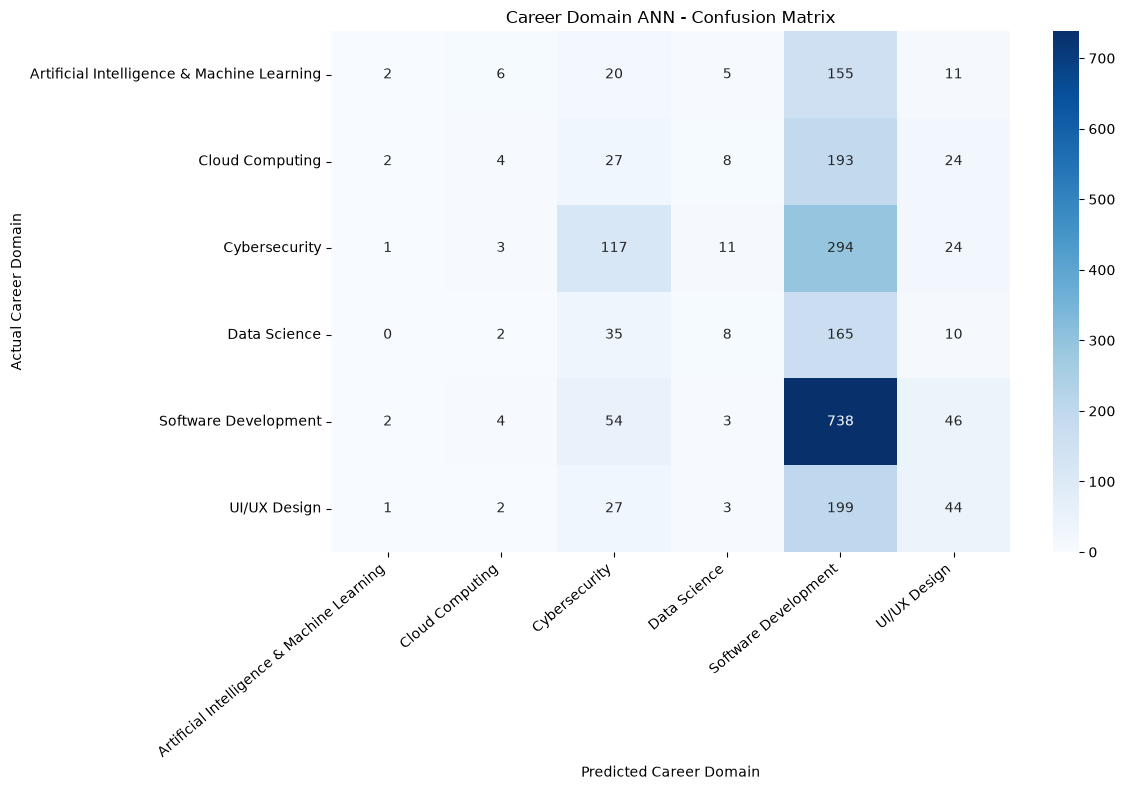

In [13]:
cm = confusion_matrix(
    y_val,
    domain_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Career Domain ANN - Confusion Matrix")
plt.xlabel("Predicted Career Domain")
plt.ylabel("Actual Career Domain")

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [14]:
baseline_candidates = [
    REPORT_DIR / "baseline_model_results.csv",
    REPORT_DIR / "baseline_classification_results.csv"
]

baseline_path = next(
    (path for path in baseline_candidates if path.exists()),
    None
)

if baseline_path is None:
    raise FileNotFoundError(
        "Baseline results CSV not found in reports/evaluation."
    )

baseline_df = pd.read_csv(baseline_path)

domain_baseline = baseline_df[
    baseline_df["Task"] == "Career Domain"
].copy()

if domain_baseline.empty:
    raise ValueError(
        "Career Domain baseline results were not found."
    )

print("Career domain baseline results loaded successfully!")

display(domain_baseline)

Career domain baseline results loaded successfully!


,Task,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC,MAE,MSE,RMSE,R2
0,Career Domain,Logistic Regression,0.424444,0.336661,0.268876,0.266877,0.366320,0.685338,NaN,NaN,NaN,NaN
1,Career Domain,Decision Tree,0.245778,0.184804,0.183009,0.183466,0.250707,0.511433,NaN,NaN,NaN,NaN
2,Career Domain,Random Forest,0.406667,0.402732,0.210045,0.171563,0.293438,0.645615,NaN,NaN,NaN,NaN


In [15]:
baseline_comparison = domain_baseline[
    [
        "Model",
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "F1_Weighted",
        "ROC_AUC"
    ]
].copy()

ann_comparison = pd.DataFrame([{
    "Model": "ANN",
    "Accuracy": domain_ann_results["Accuracy"],
    "Precision_Macro": domain_ann_results["Precision_Macro"],
    "Recall_Macro": domain_ann_results["Recall_Macro"],
    "F1_Macro": domain_ann_results["F1_Macro"],
    "F1_Weighted": domain_ann_results["F1_Weighted"],
    "ROC_AUC": domain_ann_results["ROC_AUC"]
}])

domain_comparison = pd.concat(
    [baseline_comparison, ann_comparison],
    ignore_index=True
)

domain_comparison = domain_comparison.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

print("CAREER DOMAIN - BASELINE VS ANN")
print("=" * 65)

display(domain_comparison.round(4))

CAREER DOMAIN - BASELINE VS ANN


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Logistic Regression,0.4244,0.3367,0.2689,0.2669,0.3663,0.6853
1,ANN,0.4058,0.2948,0.2254,0.2004,0.3144,0.6556
2,Decision Tree,0.2458,0.1848,0.1830,0.1835,0.2507,0.5114
3,Random Forest,0.4067,0.4027,0.2100,0.1716,0.2934,0.6456


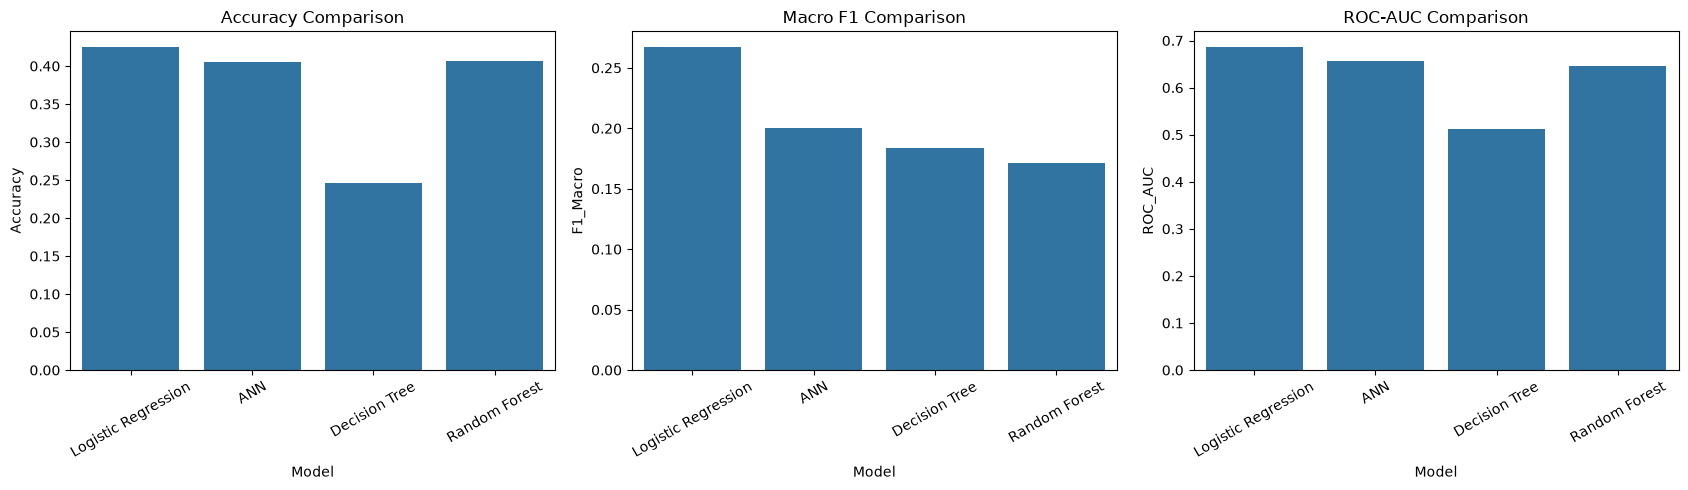

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("Accuracy", "Accuracy Comparison"),
    ("F1_Macro", "Macro F1 Comparison"),
    ("ROC_AUC", "ROC-AUC Comparison")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=domain_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [17]:
domain_ann.save(
    MODEL_DIR / "ann_domain_final.keras"
)

pd.DataFrame(
    domain_history.history
).to_csv(
    REPORT_DIR / "ann_domain_training_history.csv",
    index=False
)

domain_ann_results_df.to_csv(
    REPORT_DIR / "ann_domain_metrics.csv",
    index=False
)

domain_comparison.to_csv(
    REPORT_DIR / "domain_baseline_ann_comparison.csv",
    index=False
)

print("Career domain ANN artifacts saved successfully!")

Career domain ANN artifacts saved successfully!


In [18]:
domain_artifacts = [
    MODEL_DIR / "ann_domain_best.keras",
    MODEL_DIR / "ann_domain_final.keras",

    REPORT_DIR / "ann_domain_training_history.csv",
    REPORT_DIR / "ann_domain_metrics.csv",
    REPORT_DIR / "ann_domain_classification_report.csv",
    REPORT_DIR / "domain_baseline_ann_comparison.csv"
]

missing_artifacts = []

print("CAREER DOMAIN ANN - ARTIFACT VERIFICATION")
print("=" * 65)

for artifact in domain_artifacts:

    exists = artifact.exists()

    print(
        f"{artifact.name}:",
        "FOUND" if exists else "MISSING"
    )

    if not exists:
        missing_artifacts.append(artifact.name)

print("\nMissing artifacts:", missing_artifacts)

assert not missing_artifacts, "Some domain ANN artifacts are missing!"

print("\nALL CAREER DOMAIN ANN ARTIFACTS VERIFIED!")

CAREER DOMAIN ANN - ARTIFACT VERIFICATION
ann_domain_best.keras: FOUND
ann_domain_final.keras: FOUND
ann_domain_training_history.csv: FOUND
ann_domain_metrics.csv: FOUND
ann_domain_classification_report.csv: FOUND
domain_baseline_ann_comparison.csv: FOUND

Missing artifacts: []

ALL CAREER DOMAIN ANN ARTIFACTS VERIFIED!


In [19]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

domain_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, class_weights)
}

print("Career Domain Class Weights:")
for class_id, weight in domain_class_weights.items():
    print(f"{class_names[class_id]}: {weight:.4f}")

Career Domain Class Weights:
Artificial Intelligence & Machine Learning: 1.5695
Cloud Computing: 1.6325
Cybersecurity: 0.8483
Data Science: 1.6234
Software Development: 0.4520
UI/UX Design: 1.3462


In [20]:
weighted_domain_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(num_classes, activation="softmax")
])

weighted_domain_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

weighted_domain_ann.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,982 (74.15 KB)

 Trainable params: 18,982 (74.15 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
weighted_domain_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "ann_domain_weighted_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

weighted_domain_history = weighted_domain_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=domain_class_weights,
    callbacks=weighted_domain_callbacks,
    verbose=1
)

print("Class-weighted ANN training completed!")

Epoch 1/100
316/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2067 - loss: 1.7737
Epoch 1: val_loss improved from None to 1.71785, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_weighted_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_weighted_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2076 - loss: 1.7716 - val_accuracy: 0.2964 - val_loss: 1.7179 - learning_rate: 0.0010
Epoch 2/100
310/329 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2700 - loss: 1.7041
Epoch 2: val_loss improved from 1.71785 to 1.69332, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_weighted_best.keras

Epoch 2: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_domain_weighted_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.268

In [22]:
weighted_domain_probabilities = weighted_domain_ann.predict(
    X_val,
    verbose=0
)

weighted_domain_predictions = np.argmax(
    weighted_domain_probabilities,
    axis=1
)

weighted_domain_results = {
    "Model": "Class-Weighted ANN",

    "Accuracy": accuracy_score(
        y_val,
        weighted_domain_predictions
    ),

    "Precision_Macro": precision_score(
        y_val,
        weighted_domain_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall_Macro": recall_score(
        y_val,
        weighted_domain_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Macro": f1_score(
        y_val,
        weighted_domain_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Weighted": f1_score(
        y_val,
        weighted_domain_predictions,
        average="weighted",
        zero_division=0
    ),

    "ROC_AUC": roc_auc_score(
        y_val,
        weighted_domain_probabilities,
        multi_class="ovr",
        average="macro",
        labels=np.arange(num_classes)
    )
}

weighted_domain_results_df = pd.DataFrame([
    weighted_domain_results
])

display(weighted_domain_results_df.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Class-Weighted ANN,0.288,0.2709,0.2725,0.257,0.3053,0.6429


In [23]:
all_domain_comparison = pd.concat(
    [
        domain_comparison,
        weighted_domain_results_df
    ],
    ignore_index=True
)

all_domain_comparison = all_domain_comparison.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

print("CAREER DOMAIN - COMPLETE MODEL COMPARISON")
print("=" * 70)

display(all_domain_comparison.round(4))

CAREER DOMAIN - COMPLETE MODEL COMPARISON


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Logistic Regression,0.4244,0.3367,0.2689,0.2669,0.3663,0.6853
1,Class-Weighted ANN,0.2880,0.2709,0.2725,0.2570,0.3053,0.6429
2,ANN,0.4058,0.2948,0.2254,0.2004,0.3144,0.6556
3,Decision Tree,0.2458,0.1848,0.1830,0.1835,0.2507,0.5114
4,Random Forest,0.4067,0.4027,0.2100,0.1716,0.2934,0.6456


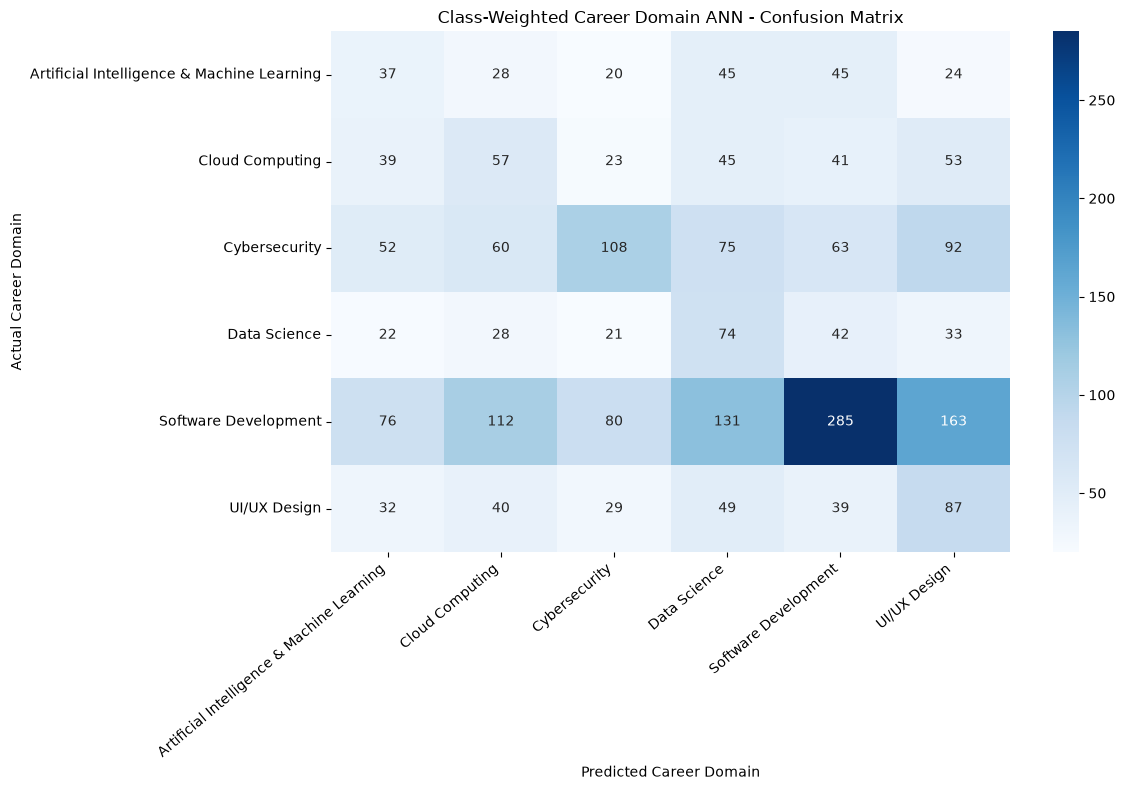

                                            precision    recall  f1-score   support

Artificial Intelligence & Machine Learning       0.14      0.19      0.16       199
                           Cloud Computing       0.18      0.22      0.20       258
                             Cybersecurity       0.38      0.24      0.30       450
                              Data Science       0.18      0.34      0.23       220
                      Software Development       0.55      0.34      0.42       847
                              UI/UX Design       0.19      0.32      0.24       276

                                  accuracy                           0.29      2250
                                 macro avg       0.27      0.27      0.26      2250
                              weighted avg       0.36      0.29      0.31      2250



In [24]:
weighted_cm = confusion_matrix(
    y_val,
    weighted_domain_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    weighted_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Class-Weighted Career Domain ANN - Confusion Matrix")
plt.xlabel("Predicted Career Domain")
plt.ylabel("Actual Career Domain")

plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_val,
        weighted_domain_predictions,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    )
)

In [25]:
weighted_domain_ann.save(
    MODEL_DIR / "ann_domain_weighted_final.keras"
)

weighted_domain_results_df.to_csv(
    REPORT_DIR / "ann_domain_weighted_metrics.csv",
    index=False
)

all_domain_comparison.to_csv(
    REPORT_DIR / "domain_complete_model_comparison.csv",
    index=False
)

print("Class-weighted domain ANN saved successfully!")

Class-weighted domain ANN saved successfully!
